# 🧪 LAB: Machine Learning to Predict Concrete Compressive Strength

In this lab, you will apply `PyTorch` to a real-world data problem. You will implement a Neural Network in `PyTorch` using the new functionalities introduced this week and compare its performance with a Support Vector Machine and Linear Regression.

Your goal is to predict the **compressive strength of concrete** (the outcome variable, *Y*) based on a set of input features (*X*), including:
**Cement, Blast Furnace Slag, Fly Ash, Water, Superplasticizer, Coarse Aggregate, Fine Aggregate, and Age.**

This dataset and problem are based on the following paper:

- I-Cheng Yeh, "Modeling of strength of high performance concrete using artificial neural networks," Cement and Concrete Research, Vol. 28, No. 12, pp. 1797-1808 (1998). [Link to the paper](yeh1998.pdf).


---

**Collaboration Note**: This assignment is designed to support collaborative work. We encourage you to divide tasks among group members so that everyone can contribute meaningfully. Many components of the assignment can be approached in parallel or split logically across team members. Good coordination and thoughtful integration of your work will lead to a stronger final result.

---

In total, this lab assignment will be worth **100 points**.

--- 
**Submission notes**:

* Write down all group members' names, or at least the group name (if you have one and you previously provided it), in the first cell of the notebook.

* Verify that the notebook runs as expected and that all required outputs are included.

NAME(s) = ""

## 0. Overall Instructions 

In this lab, you will work with three models: a **Neural Network**, a **Support Vector Machine (SVM)**, and some form of **Linear Regression**. Each should meet the following requirements:

- **Do not tune the models**. For example, for the Neural Network, choose any number of layers and hidden units you prefer; for the SVM, select a kernel of your choice (e.g., linear, RBF, polynomial), etc.
    - choose two layers, 16 nodes per layer, ReLU

- **Evaluate model performance using k-fold cross-validation**. That is, run each model using a chosen number of folds (*k*), and report the average performance across all folds. You may select the value of *k* that you want.

- **Be careful with data preprocessing**. Apply all preprocessing steps properly to avoid data leakage (e.g. standardizing features before data splitting)

## 1. Pre-implementation Group Discussion (15 points)

In your group, discuss, agree on, and elaborate the following points:

- **Descriptive analysis**. Identify what exploratory or descriptive analyses you can perform to better understand the relationship between each input variable and the outcome. Consider both visual (e.g., scatter plots, histograms) and statistical summaries.
   - df.describe
   - df.shape 
   - df.info
   - corr matrix
   - Pairplot
   - KDE histogram of y

- **Data preprocessing**. Decide what preprocessing steps are necessary given that you will be using neural networks. 
    - remove nulls, standardize

- **Model configuration**. Specify which cost function and output layer activation are most appropriate for your problem type (e.g., regression vs. classification). Explain your reasoning based on the nature of the outcome variable.
    - NN: MSE, RL: MSE, SVM: epsilon insenstive loss
    - regression problem

- **Performance evaluation**. Describe how you will perform k-fold cross-validation to assess your model’s performance. Include how you will divide the data, compute metrics across folds, and report the final averaged results.
    - 80/20 split
    - final report should have train accuracy, holdout accuracy, mean of both, train/holdout cost, mean of both

## 2. Descriptive analysis (10 points)

Apply the descriptive analyses that your group agreed upon in the previous section.

**Load the dataset before beginning the descriptive analysis; you will also use it in the following sections.**

In [1]:
# load xls file
import pandas as pd
data = pd.read_excel("Concrete_Data.xls")
data.head()

,Cement (component 1)(kg in a m^3 mixture),Blast Furnace Slag (component 2)(kg in a m^3 mixture),Fly Ash (component 3)(kg in a m^3 mixture),Water (component 4)(kg in a m^3 mixture),Superplasticizer (component 5)(kg in a m^3 mixture),Coarse Aggregate (component 6)(kg in a m^3 mixture),Fine Aggregate (component 7)(kg in a m^3 mixture),Age (day),"Concrete compressive strength(MPa, megapascals)"
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.986111
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.887366
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.269535
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.052780
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.296075


In [2]:
# shorter column names so the pairplot / corr matrix are readable
data.columns = ["cement", "slag", "fly_ash", "water", "superplasticizer",
                "coarse_agg", "fine_agg", "age", "strength"]
print("duplicate rows:", data.duplicated().sum())
data.head()

duplicate rows: 25


,cement,slag,fly_ash,water,superplasticizer,coarse_agg,fine_agg,age,strength
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.986111
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.887366
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.269535
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.052780
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.296075


In [3]:
# df.shape for getting the dimensions of the DataFrame
data.shape

(1030, 9)

In [4]:
# df.info() for getting a concise summary of the DataFrame
data.info()
# no-non null data types--column names kind of suck though
# all datatypes look good

<class 'pandas.DataFrame'>
RangeIndex: 1030 entries, 0 to 1029
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   cement            1030 non-null   float64
 1   slag              1030 non-null   float64
 2   fly_ash           1030 non-null   float64
 3   water             1030 non-null   float64
 4   superplasticizer  1030 non-null   float64
 5   coarse_agg        1030 non-null   float64
 6   fine_agg          1030 non-null   float64
 7   age               1030 non-null   int64  
 8   strength          1030 non-null   float64
dtypes: float64(8), int64(1)
memory usage: 72.6 KB


In [5]:
# data.describe() for getting a statistical summary of the DataFrame
data.describe(include='all')

,cement,slag,fly_ash,water,superplasticizer,coarse_agg,fine_agg,age,strength
count,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000
mean,281.165631,73.895485,54.187136,181.566359,6.203112,972.918592,773.578883,45.662136,35.817836
std,104.507142,86.279104,63.996469,21.355567,5.973492,77.753818,80.175427,63.169912,16.705679
min,102.000000,0.000000,0.000000,121.750000,0.000000,801.000000,594.000000,1.000000,2.331808
25%,192.375000,0.000000,0.000000,164.900000,0.000000,932.000000,730.950000,7.000000,23.707115
50%,272.900000,22.000000,0.000000,185.000000,6.350000,968.000000,779.510000,28.000000,34.442774
75%,350.000000,142.950000,118.270000,192.000000,10.160000,1029.400000,824.000000,56.000000,46.136287
max,540.000000,359.400000,200.100000,247.000000,32.200000,1145.000000,992.600000,365.000000,82.599225


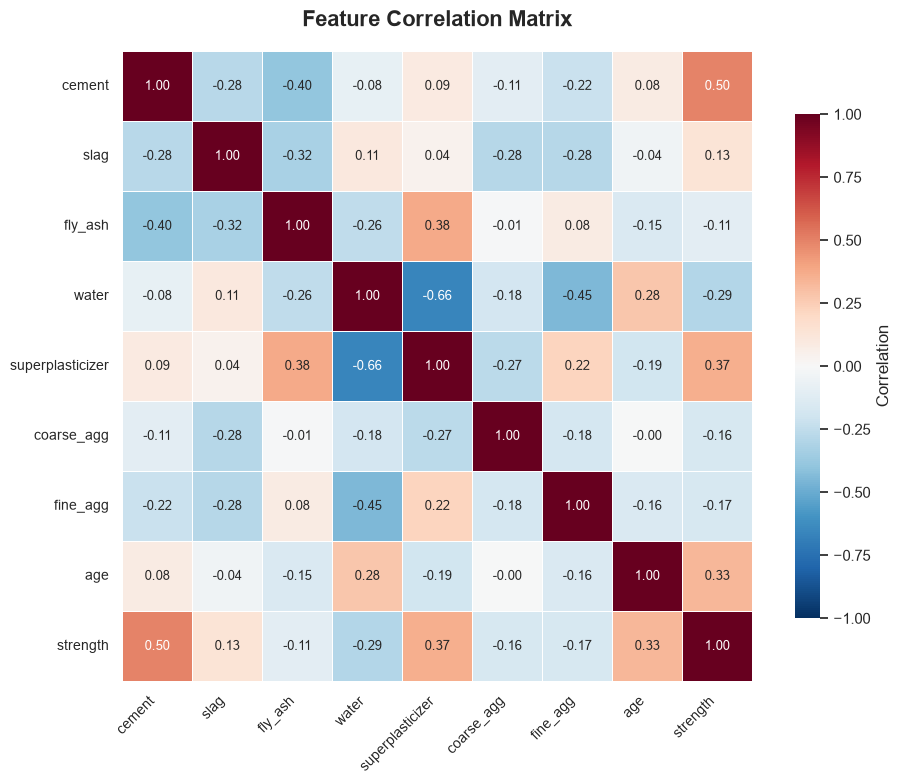

In [6]:
# df.corr() for getting the correlation matrix of the DataFrame
# make a visualization of the correlation matrix
import seaborn as sns
import matplotlib.pyplot as plt
corr_matrix = data.corr()
sns.set_theme(style="white", font_scale=1.0)
plt.figure(figsize=(10, 8))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=0.5,
    linecolor="white",
    cbar_kws={"shrink": 0.8, "label": "Correlation"},
    annot_kws={"size": 9}
)
plt.title("Feature Correlation Matrix", fontsize=16, fontweight="bold", pad=18)
plt.xticks(rotation=45, ha="right", fontsize=10)
plt.yticks(rotation=0, fontsize=10)
plt.tight_layout()
plt.show()

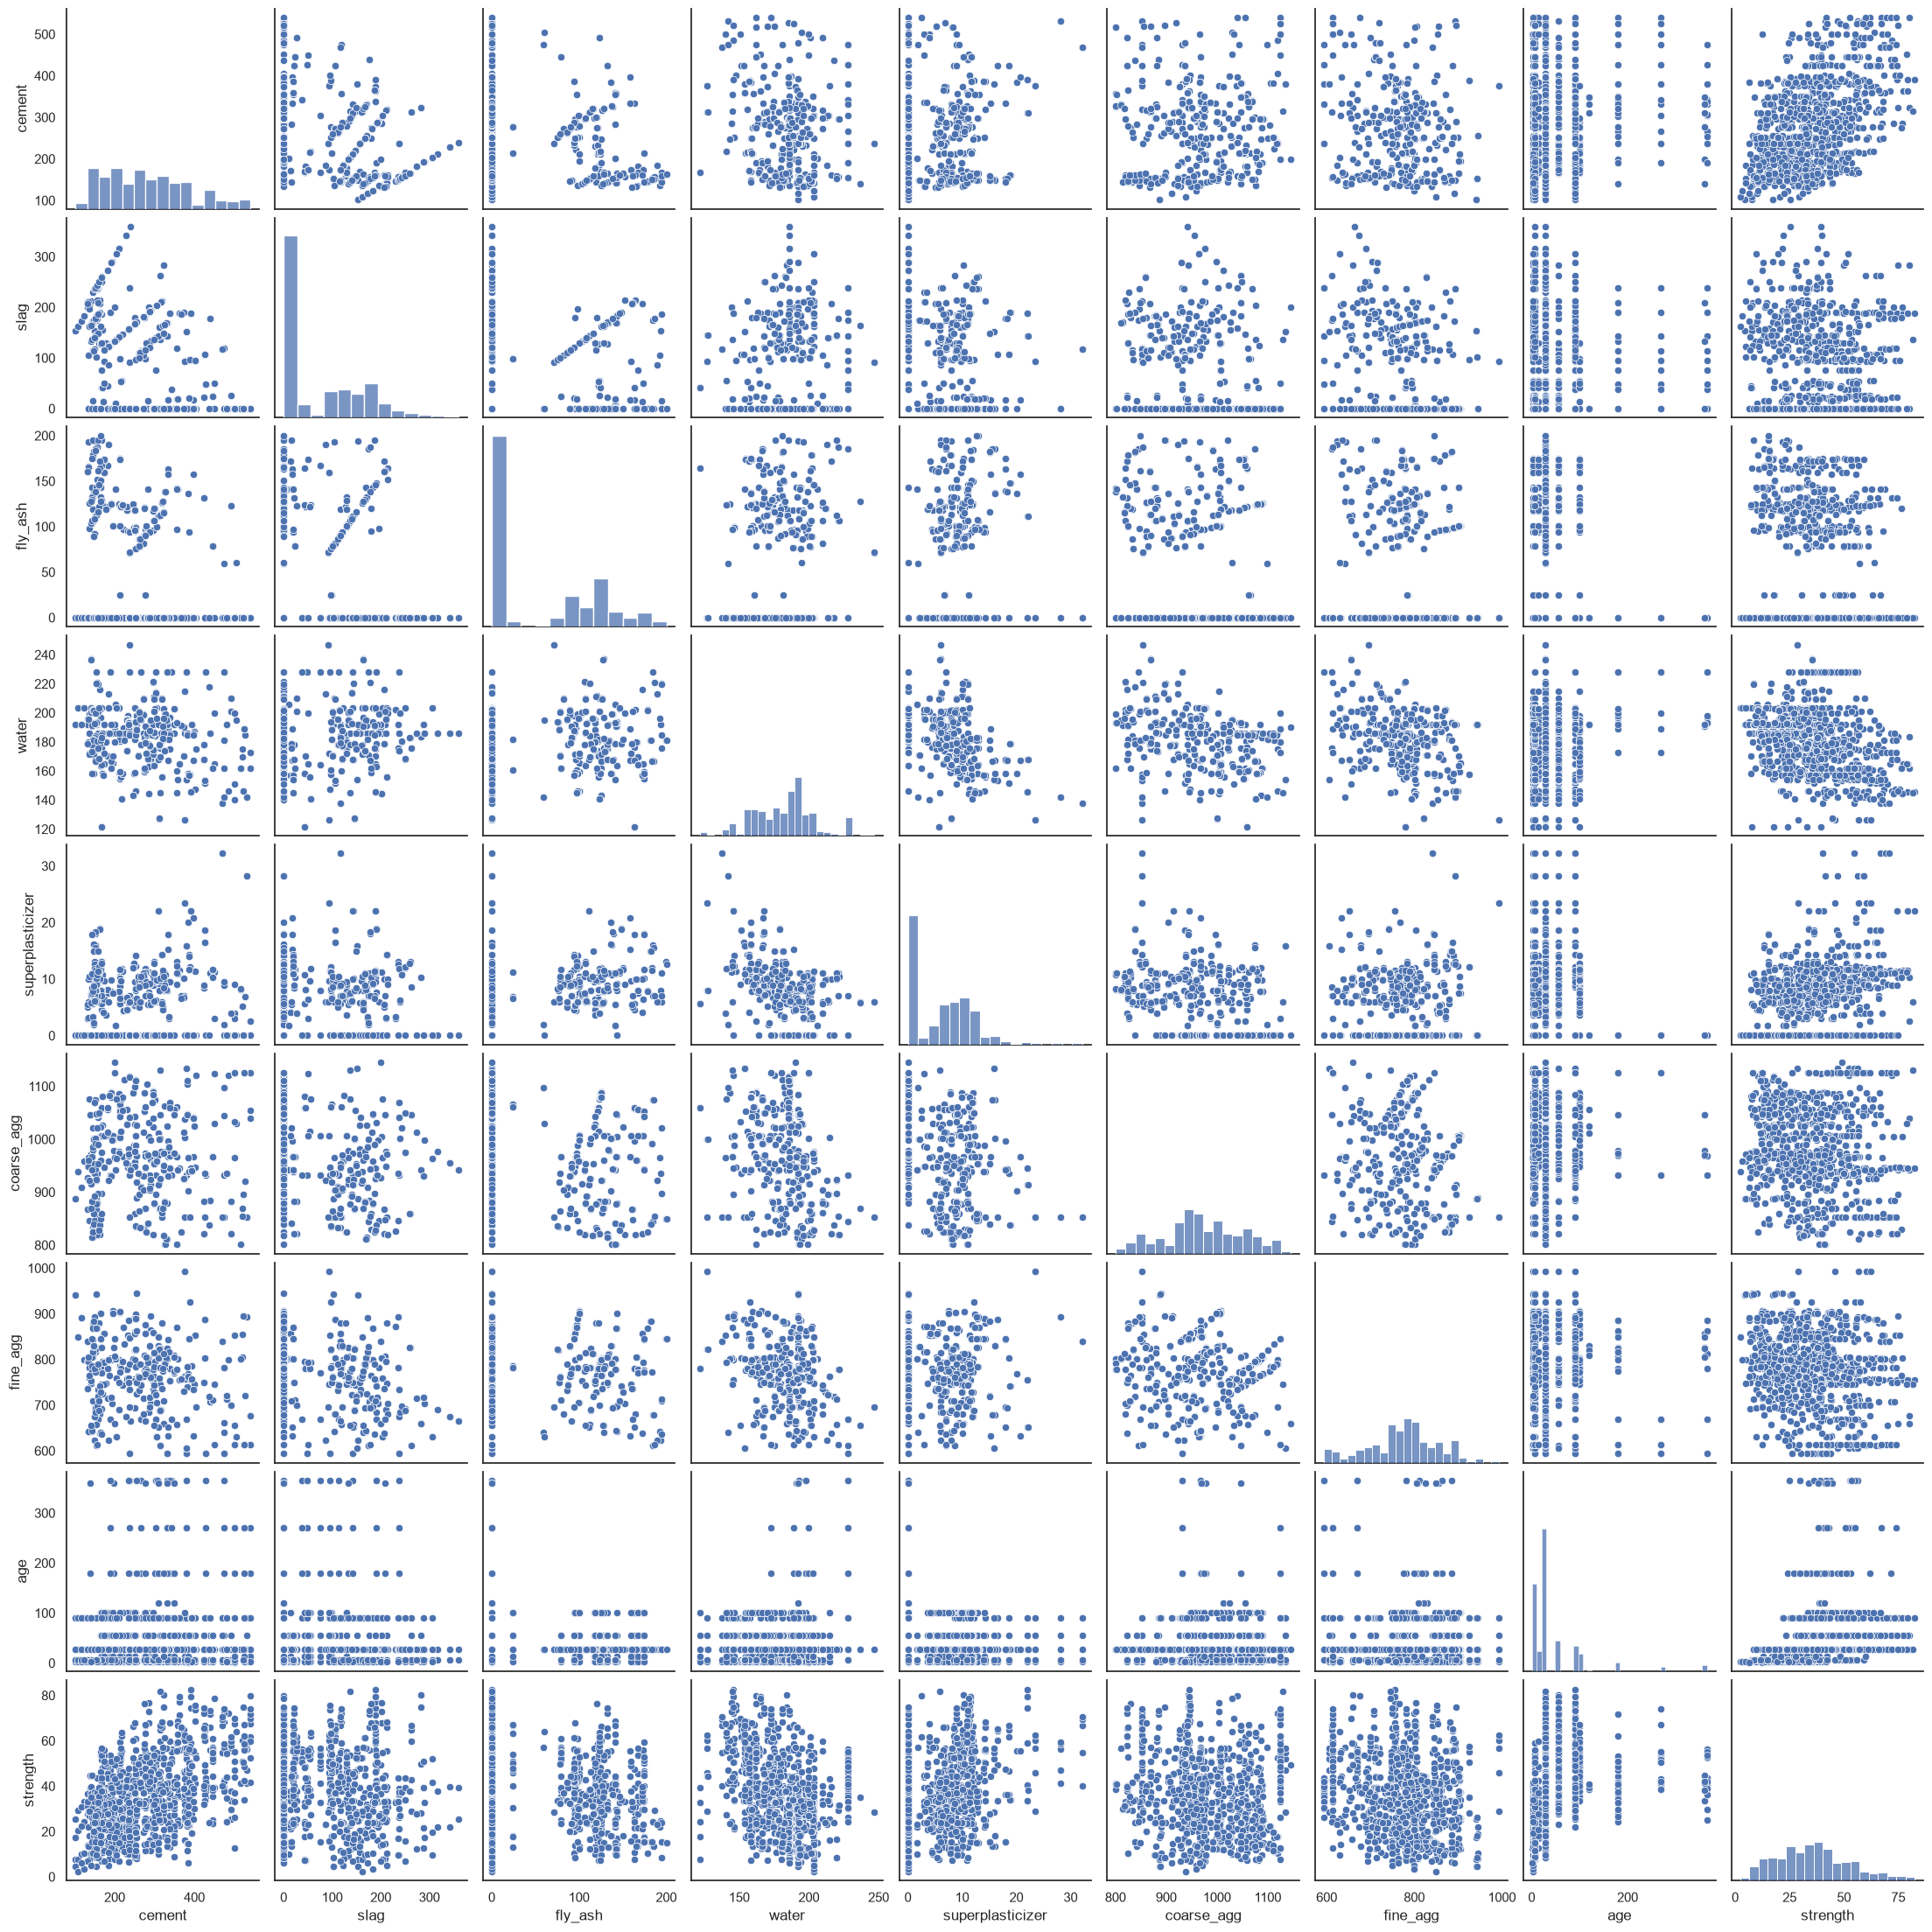

In [7]:
sns.pairplot(data)
plt.show()

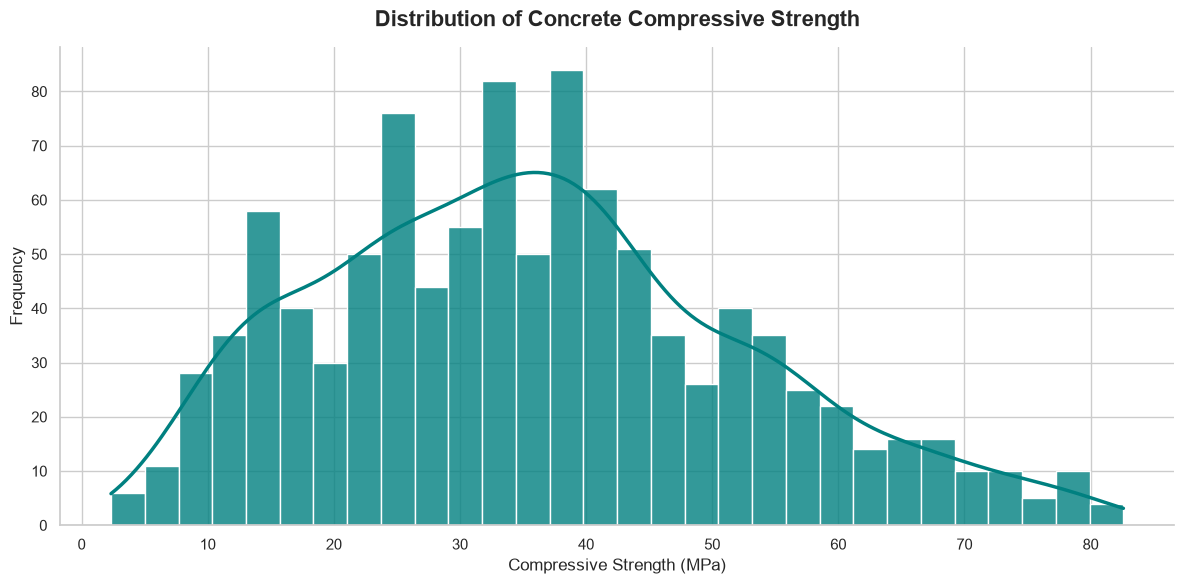

In [8]:
sns.set_theme(style="whitegrid", context="notebook")

plt.figure(figsize=(12, 6))

sns.histplot(
    data=data,
    x=data.columns[-1],
    bins=30,
    kde=True,
    color="teal", #nice color
    edgecolor="white",
    alpha=0.8,
    line_kws={"linewidth": 2.5}
)

plt.title("Distribution of Concrete Compressive Strength",
          fontsize=16, fontweight="bold", pad=15)
plt.xlabel("Compressive Strength (MPa)", fontsize=12)
plt.ylabel("Frequency", fontsize=12)

sns.despine()
plt.tight_layout()
plt.show()


## 3. Neural Network (40 points)

Implement a neural network as you did in the previous lab, but this time leverage the new functionalities introduced this week. Specifically:

- Your class implementing the neural network should inherit from nn.Module.

- Use `nn.Linear` for the linear transformations between layers, `nn.ReLU` for the hidden-layer activations, and the appropriate activation function for the output layer (e.g., `nn.Sigmoid` for binary classification).

- Use the appropriate cost function from `torch.nn` for your task (e.g., `nn.MSELoss`, `nn.BCELoss`).

- Use Adam from `torch.optim` as the optimizer.

- Use `DataLoader` to efficiently do batch processing. You may choose the batch size freely.

Once you have implemented this class, create an instance of it, then train and evaluate your model on the lab dataset.

**Remember to follow the general requirements regarding model tuning, evaluation, and data preprocessing described earlier.**

In [9]:
# Imports + data prep
import numpy as np
import torch
import torch.nn as nn
from torch import optim
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split, KFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score

df = data.drop_duplicates()  # duplicates could land in both train and test folds
X = df.drop(columns="strength").to_numpy()
y = df["strength"].to_numpy()

# split dataset, 20% holdout; k-fold CV runs on the other 80%
X_train, X_holdout, y_train, y_holdout = train_test_split(X, y, test_size=0.2, random_state=42)
kf = KFold(n_splits=5, shuffle=True, random_state=123)
X_train.shape, X_holdout.shape

((804, 8), (201, 8))

In [ ]:
# this nn will have 2 layers, 16 nodes per layer, both ReLU
# output layer is linear (no activation) because this is regression
class MyModel(nn.Module):
    def __init__(self):
        super().__init__()
        l1 = nn.Linear(8, 16)
        a1 = nn.ReLU()
        l2 = nn.Linear(16, 16)
        a2 = nn.ReLU()
        l3 = nn.Linear(16, 1)
        l = [l1, a1, l2, a2, l3]
        self.module_list = nn.ModuleList(l)

    def forward(self, X):
        for f in self.module_list:
            X = f(X)
        return X

    def fit(self, X, y, n_epochs=200, batch_size=16, lr=0.01):
        X = torch.tensor(X, dtype=torch.float32)
        y = torch.tensor(y, dtype=torch.float32).reshape(-1, 1)
        train_loader = DataLoader(TensorDataset(X, y), batch_size=batch_size, shuffle=True)

        cost_function = nn.MSELoss()
        optimizer = optim.Adam(self.parameters(), lr=lr)

        self.train_costs = []
        for epoch in range(n_epochs):
            self.train()
            running_cost = 0
            for x_batch, y_batch in train_loader:
                optimizer.zero_grad()
                y_pred = self(x_batch)
                cost = cost_function(y_pred, y_batch)
                cost.backward()
                optimizer.step() # the adam optimizer function updates the model parameters based on the computed gradients
                running_cost += cost.item()
            self.train_costs.append(running_cost / len(train_loader)) # average training cost for epoch defined by cost of epoch / number of batches
        return self

    def predict(self, X):
        self.eval()
        with torch.no_grad():
            return self(torch.tensor(X, dtype=torch.float32)).numpy().flatten()

In [11]:
# k-fold CV: the scaler is fit on each training fold only (no leakage)
nn_folds = []
for fold, (train_idx, test_idx) in enumerate(kf.split(X_train)):
    scaler = StandardScaler()
    X_train_kfold = scaler.fit_transform(X_train[train_idx])
    X_test_kfold = scaler.transform(X_train[test_idx])
    y_train_kfold, y_test_kfold = y_train[train_idx], y_train[test_idx]

    torch.manual_seed(1234)
    model = MyModel().fit(X_train_kfold, y_train_kfold)
    y_pred_train_kfold = model.predict(X_train_kfold)
    y_pred_test_kfold = model.predict(X_test_kfold)

    nn_folds.append([mean_squared_error(y_train_kfold, y_pred_train_kfold), mean_squared_error(y_test_kfold, y_pred_test_kfold),
                     r2_score(y_train_kfold, y_pred_train_kfold), r2_score(y_test_kfold, y_pred_test_kfold)])
    print(f"Fold {fold+1}: Train MSE = {nn_folds[-1][0]:.2f}, Test MSE = {nn_folds[-1][1]:.2f}, Test R2 = {nn_folds[-1][3]:.3f}")

nn_folds = pd.DataFrame(nn_folds, columns=["cv_train_mse", "cv_test_mse", "cv_train_r2", "cv_test_r2"])
nn_folds.mean()

Fold 1: Train MSE = 21.46, Test MSE = 37.79, Test R2 = 0.829
Fold 2: Train MSE = 25.07, Test MSE = 44.71, Test R2 = 0.812
Fold 3: Train MSE = 27.63, Test MSE = 30.91, Test R2 = 0.882
Fold 4: Train MSE = 24.17, Test MSE = 32.20, Test R2 = 0.892
Fold 5: Train MSE = 24.82, Test MSE = 37.40, Test R2 = 0.848


cv_train_mse    24.631682
cv_test_mse     36.601604
cv_train_r2      0.903717
cv_test_r2       0.852664
dtype: float64

Holdout MSE: 42.12, Holdout R2: 0.859


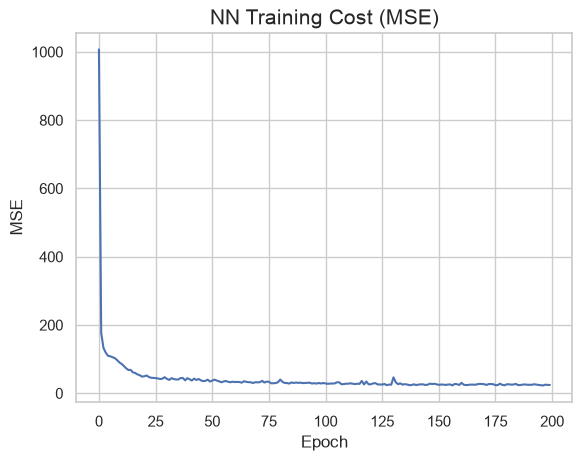

In [12]:
# final fit on the full 80% train set, evaluated once on the untouched holdout set
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_holdout_scaled = scaler.transform(X_holdout)

torch.manual_seed(1234)
model = MyModel().fit(X_train_scaled, y_train)
y_pred_holdout = model.predict(X_holdout_scaled)
print(f"Holdout MSE: {mean_squared_error(y_holdout, y_pred_holdout):.2f}, Holdout R2: {r2_score(y_holdout, y_pred_holdout):.3f}")

plt.plot(model.train_costs)
plt.title("NN Training Cost (MSE)", size=15)
plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.show()

## 4. Replication (10 points)

Replicate your neural network experiment using the corresponding model class from `scikit-learn`: https://scikit-learn.org/stable/api/sklearn.neural_network.html. Be sure to apply the same neural network architecture as well as the same procedures for model evaluation and preprocessing to ensure a fair comparison.

**Remember**: Follow the general requirements regarding model tuning, evaluation, and data preprocessing described earlier.

In [18]:
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_validate

def cv_report(pipe, name):
    # same KFold as the NN; scaler lives inside the pipeline, so it is refit per fold
    cv_output = cross_validate(pipe, X_train, y_train, cv=kf, return_train_score=True,
                        scoring={"mse": "neg_mean_squared_error", "r2": "r2"})  # sklearn only maximizes scores, so MSE comes back negated; flipped with - below
    pipe.fit(X_train, y_train)
    y_pred_holdout = pipe.predict(X_holdout)
    res = pd.Series({"cv_train_mse": -cv_output["train_mse"].mean(), "cv_test_mse": -cv_output["test_mse"].mean(),
                     "cv_train_r2": cv_output["train_r2"].mean(), "cv_test_r2": cv_output["test_r2"].mean(),
                     "holdout_mse": mean_squared_error(y_holdout, y_pred_holdout), "holdout_r2": r2_score(y_holdout, y_pred_holdout)}, name=name)
    print(res.round(3))
    return res

In [19]:
# same architecture/training setup as the PyTorch model
pipeline_MLP = Pipeline([
    ("scaler", StandardScaler()),
    ("mlp", MLPRegressor(hidden_layer_sizes=(16, 16), activation="relu", solver="adam",
                         learning_rate_init=0.01, batch_size=16, max_iter=200, random_state=1234))
])
mlp_res = cv_report(pipeline_MLP, "sklearn MLP")

cv_train_mse    24.966
cv_test_mse     40.136
cv_train_r2      0.903
cv_test_r2       0.838
holdout_mse     35.709
holdout_r2       0.880
Name: sklearn MLP, dtype: float64


## 5. Comparison (20 points)

Apply a Support Vector Machine (SVM) and Linear Regression model to the dataset, and compare their performance with that of your Neural Network.

Discuss any similarities or differences you observe in their results and provide possible explanations for these patterns.

Be sure to apply the k-fold cross-validation procedure to ensure a fair comparison across all models.

**Remember**: Follow the general requirements regarding model tuning, evaluation, and data preprocessing described earlier.

In [14]:
# let's make a support vector machine of the data with 80/20 train-test split, final report with the following: train/holdout accuracy, mean of both, train/holdout cost, mean of both, cost is epsilon-insensitive loss
from sklearn.svm import SVR

pipeline_SVR = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", SVR(kernel="rbf", C=1, epsilon=0.1))  # default C, not tuned
])
svm_res = cv_report(pipeline_SVR, "SVM (RBF)")

# epsilon-insensitive cost on the holdout set: mean(max(0, |y - y_hat| - eps))
eps_loss = np.maximum(0, np.abs(y_holdout - pipeline_SVR.predict(X_holdout)) - 0.1).mean()
print(f"Holdout epsilon-insensitive loss: {eps_loss:.3f}")

cv_train_mse     97.537
cv_test_mse     104.947
cv_train_r2       0.619
cv_test_r2        0.586
holdout_mse     119.349
holdout_r2        0.600
Name: SVM (RBF), dtype: float64
Holdout epsilon-insensitive loss: 8.246


In [15]:
from sklearn.linear_model import LinearRegression

pipeline_LR = Pipeline([
    ("scaler", StandardScaler()),
    ("lr", LinearRegression())
])
lr_res = cv_report(pipeline_LR, "Linear Regression")

cv_train_mse     99.606
cv_test_mse     104.139
cv_train_r2       0.611
cv_test_r2        0.586
holdout_mse     125.265
holdout_r2        0.580
Name: Linear Regression, dtype: float64


In [ ]:
nn_res = pd.Series({**nn_folds.mean().to_dict(),
                    "holdout_mse": mean_squared_error(y_holdout, y_pred_holdout), "holdout_r2": r2_score(y_holdout, y_pred_holdout)}, name="PyTorch NN")
results = pd.DataFrame([nn_res, mlp_res, svm_res, lr_res])
results["cv_test_rmse"] = np.sqrt(results["cv_test_mse"]) # for unit consistency and interpretability
results.round(3)

,cv_train_mse,cv_test_mse,cv_train_r2,cv_test_r2,holdout_mse,holdout_r2,cv_test_rmse
PyTorch NN,24.632,36.602,0.904,0.853,42.118,0.859,6.050
sklearn MLP,24.966,40.136,0.903,0.838,35.709,0.880,6.335
SVM (RBF),97.537,104.947,0.619,0.586,119.349,0.600,10.244
Linear Regression,99.606,104.139,0.611,0.586,125.265,0.580,10.205


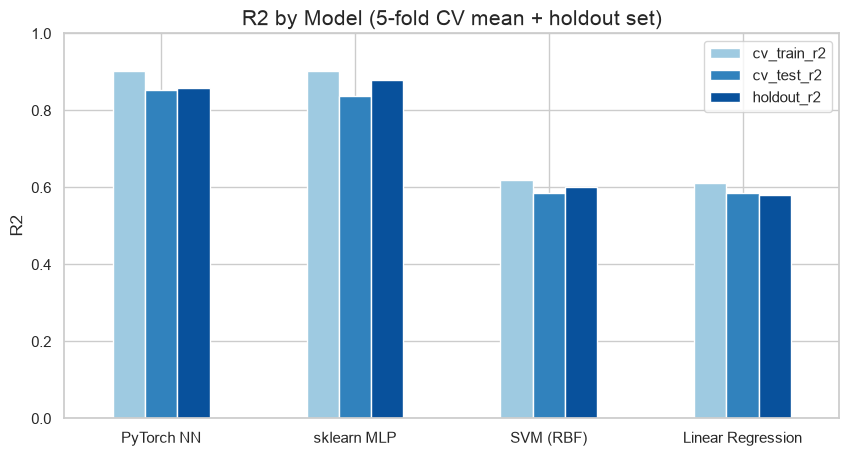

In [17]:
results[["cv_train_r2", "cv_test_r2", "holdout_r2"]].plot(kind="bar", figsize=(10, 5), color=["#9ecae1", "#3182bd", "#08519c"])
plt.title("R2 by Model (5-fold CV mean + holdout set)", size=15)
plt.ylabel("R2")
plt.xticks(rotation=0)
plt.ylim(0, 1)
plt.show()

### Discussion
Both neural networks clearly outperform the other two models. The PyTorch NN and sklearn's MLP reach a CV test R² of about 0.84–0.85 (RMSE ≈ 6 MPa), while the SVM and Linear Regression only reach about 0.59 (RMSE ≈ 10 MPa). The two neural networks agree closely because they share the same architecture, optimizer, learning rate, batch size and number of epochs; the small gap between them (about 0.015 R²) comes from different weight initialization and from sklearn adding L2 regularization (`alpha`) by default. Linear Regression underfits because compressive strength is not linear in its inputs: age has a steep early gain that then plateaus (skew ≈ 3.3), and there are interactions such as the water/cement ratio that a linear model cannot represent. This is why its train and CV test R² are both low and close together, a sign of high bias and low variance. The SVM scores about the same as Linear Regression, but for a different reason. The RBF kernel can model nonlinearity, but with the untuned default `C=1` and an unscaled target (MPa, std ≈ 17), the regularization is very strong relative to the size of the errors, so the fit is overly flat. Raising C or scaling y would likely close much of the gap, but we left it untuned as the lab requires. Finally, the neural networks show a modest train/test gap (R² 0.90 vs 0.85), while the linear models show almost none, which is expected given how much more flexible the networks are. The holdout scores track the CV means, which suggests the CV estimates are reliable.

## 6. Collaboration Reflection (5 points)

As a group, identify **one specific challenge or inefficiency** you encountered while working on this lab. In 3–5 sentences:

1. Briefly describe what happened and how it affected your work.
2. Identify one concrete action your group will take to avoid or better manage this issue in the next lab.

If your group encountered no major problem, identify one aspect of your collaboration that could still be improved.

YOUR TEXT HERE